# 02 — Invasion front and spread rate

**Goal:** estimate how fast the invasion front moves and where it will be in 2030, with uncertainty.

Plan:
1. Aggregate records into 25 km grid cells and get the **first detection year** per cell.
2. Compare front estimators, from naive to robust.
3. Build a robust estimator and quantify its uncertainty.
4. **Backtest:** predict 2016–2025 with data up to 2015, and compare with what happened.
5. Forecast 2030.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from download import download_australia_outline
from front import AUSTRALIAN_ALBERS, front_positions, records_to_cells, speed_km_per_year

FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000

records = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "rhinella_marina_clean.csv")
australia = download_australia_outline().to_crs(AUSTRALIAN_ALBERS)
cells = records_to_cells(records, CELL_SIZE_M)
print(f"{len(records):,} records -> {len(cells):,} occupied cells of 25 x 25 km")
cells["n_records"].describe(percentiles=[0.25, 0.5, 0.75]).round(1)

37,719 records -> 1,423 occupied cells of 25 x 25 km


count    1423.0
mean       26.5
std        86.2
min         1.0
25%         1.0
50%         4.0
75%        14.0
max      1271.0
Name: n_records, dtype: float64

A quarter of the cells have a single record: in much of northern Australia, the first detection depends on one person reporting one toad. **First detection is not first arrival**: the gap between them (detection lag) is larger where sampling is sparse.

## 1. First detection year per cell

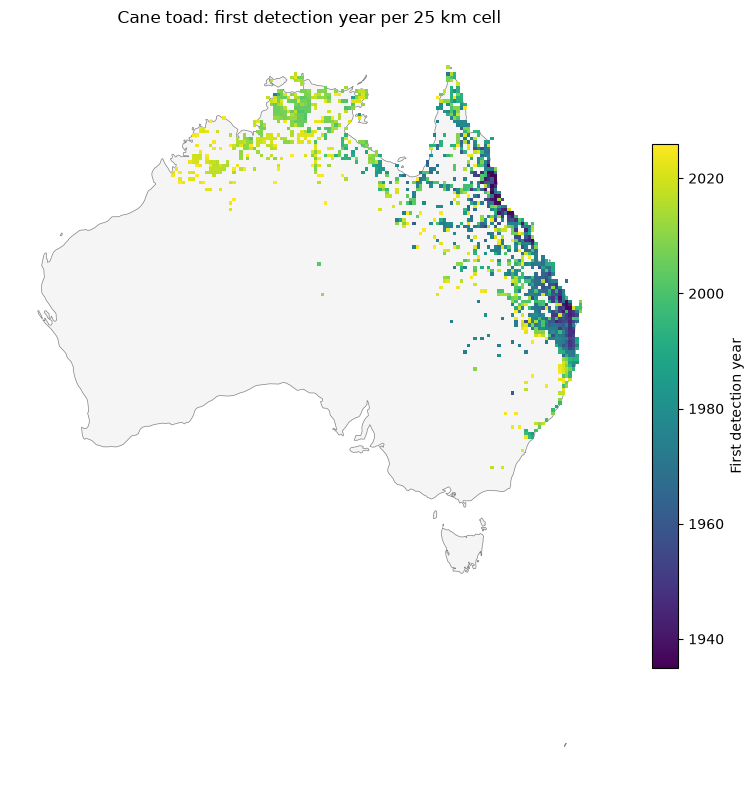

In [2]:
def plot_cells(ax, cells, column, cmap, label):
    norm = plt.Normalize(cells[column].min(), cells[column].max())
    colormap = plt.get_cmap(cmap)
    for row in cells.itertuples():
        ax.add_patch(Rectangle(
            (row.cx * CELL_SIZE_M, row.cy * CELL_SIZE_M), CELL_SIZE_M, CELL_SIZE_M,
            color=colormap(norm(getattr(row, column))), linewidth=0,
        ))
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=colormap), ax=ax, label=label, shrink=0.7)


fig, ax = plt.subplots(figsize=(9, 8))
australia.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
plot_cells(ax, cells, "first_year", "viridis", "First detection year")
ax.set_axis_off()
ax.set_title("Cane toad: first detection year per 25 km cell")
plt.tight_layout()
plt.savefig(FIGURES / "02_first_detection_map.png", dpi=150)

## 2. There is no single origin

A natural first idea is to measure distance from the introduction site (Gordonvale, 1935). But the data show that by 1940 toads were already spread along the Queensland coast: they were released in several sugar-cane districts, not at one point.

In [3]:
early = cells.loc[cells["first_year"] <= 1940]
print(f"{len(early)} cells occupied by 1940, spanning latitudes {early['lat'].min():.1f} to {early['lat'].max():.1f}")

30 cells occupied by 1940, spanning latitudes -25.5 to -16.5


So instead of distance from an origin, we measure the **position of each front along an axis**:

- **Western front** (cells west of 141°E): how far west it reached (x coordinate, km).
- **Southern front** (cells south of 25°S and east of 148°E): how far south it reached (y coordinate, km).

Both coordinates are in Australian Albers (EPSG:3577), an equal-area projection in metres.

In [4]:
FRONTS = {
    "west": (lambda c: c["lon"] < 141, "x_km"),
    "south": (lambda c: (c["lat"] < -25) & (c["lon"] > 148), "y_km"),
}
YEARS = range(1960, 2026)

## 3. Comparing front estimators

The front at year *t* is the most advanced occupied cell. Three versions, from naive to robust:

| Estimator | Definition | Weakness |
|---|---|---|
| **Naive** | Most advanced cell | A single transported toad moves the front hundreds of km |
| **k-th cell** | 3rd most advanced cell | Robust to 2 outliers, but not to an established jump population (e.g. Sydney) |
| **Contiguous** | 3rd most advanced cell *connected* to the core range (gaps ≤ 75 km) | Depends on the gap threshold, which depends on sampling density |

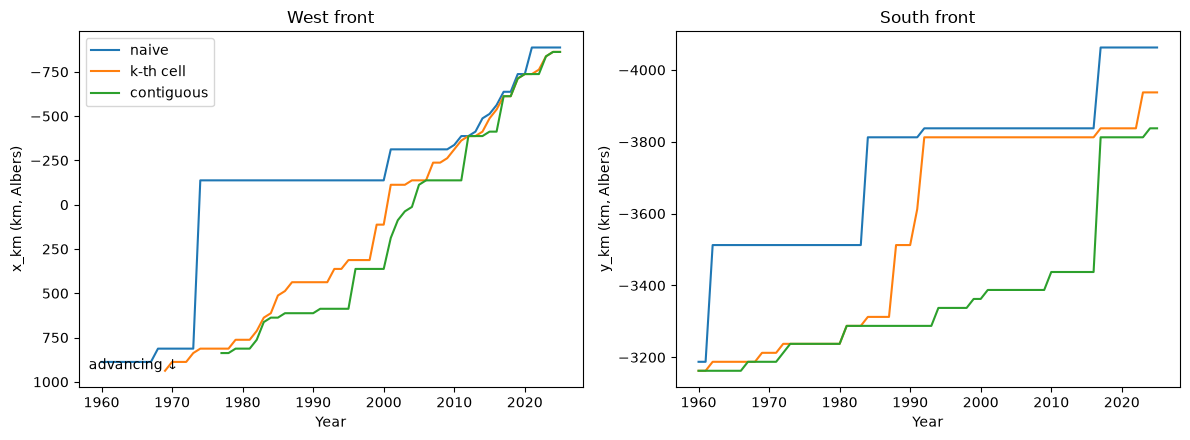

In [5]:
estimators = {
    "naive": dict(k=1),
    "k-th cell": dict(k=3),
    "contiguous": dict(k=3, seed_year=1940, max_gap_cells=3),
}
positions = {name: front_positions(cells, YEARS, FRONTS, **params) for name, params in estimators.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, front in zip(axes, FRONTS):
    for name, df in positions.items():
        ax.plot(df.index, df[front], label=name)
    ax.invert_yaxis()
    ax.set(title=f"{front.capitalize()} front", xlabel="Year", ylabel=f"{FRONTS[front][1]} (km, Albers)")
axes[0].legend()
axes[0].annotate("advancing ↓", xy=(0.02, 0.05), xycoords="axes fraction")
plt.tight_layout()
plt.savefig(FIGURES / "02_front_estimators.png", dpi=150)

In [6]:
DECADES = [(1966, 1975), (1976, 1985), (1986, 1995), (1996, 2005), (2006, 2015), (2016, 2025)]

speed_table = pd.DataFrame({
    (front, name): {f"{a}-{b}": speed_km_per_year(df[front], a, b) for a, b in DECADES}
    for front in FRONTS
    for name, df in positions.items()
}).round(1)
speed_table

west                      south                     
          naive k-th cell contiguous naive k-th cell contiguous
1966-1975  99.4      20.5        NaN  -0.0       6.8        8.2
1976-1985  -0.0      31.1       29.2  29.1      10.0        7.6
1986-1995  -0.0      15.0        3.8   3.6      63.6        4.8
1996-2005  26.5      62.0       56.7  -0.0      -0.0        7.0
2006-2015  23.0      33.6       37.7  -0.0      -0.0        7.3
2016-2025  39.5      36.1       42.4  12.3      14.1       22.9

Speeds in km/year, positive = advancing. **None of these estimators is reliable:**

- **Naive** gives 0 for whole decades and absurd jumps: a single record far ahead "freezes" the front until the real front catches up.
- **k-th cell** is better in the west, but in the south it is driven by toads transported to New South Wales.
- **Contiguous** fails in both directions. In the sparsely sampled west, gaps break the chain of cells. In the south, the opposite happens: since 2017, citizen-science records (FrogID) fill the gaps along the coast and "connect" the transported population in Sydney with the real front, producing a fake jump of hundreds of km.

The lesson: **any estimator based on the single most advanced cells inherits the noise of the most unusual records.** We need one that uses all the data and down-weights outliers.

## 4. A robust estimator: arrival time per strip + Theil–Sen

1. Split the western region into **50 km strips** along the x axis.
2. The **arrival year** of a strip is the earliest detection in any of its cells.
3. Fit **advance (km) vs arrival year** with **Theil–Sen regression**: the slope is the median of the slopes between all pairs of points, so a few outliers (early jumps, late detections) barely move it. The slope is the spread rate, with a 95% confidence interval.

We use strips first detected from 1996 onwards, when the front was moving through the Northern Territory into Western Australia.

Western front, 1996-2025: 42.9 km/year (95% CI 39.6 to 46.9), 23 strips


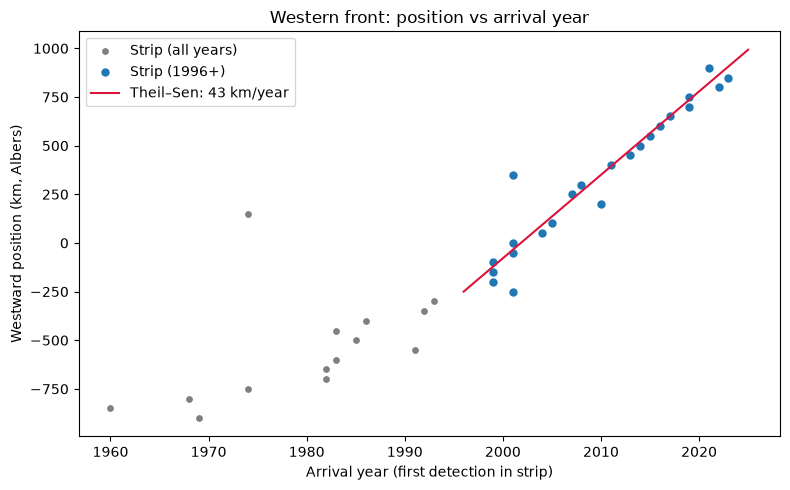

In [7]:
from scipy.stats import theilslopes
from front import strip_arrivals

STRIP_KM = 50
west_cells = cells.loc[cells["lon"] < 141]
strips = strip_arrivals(west_cells, "x_km", STRIP_KM)
recent = strips.loc[strips["arrival_year"] >= 1996]

slope, intercept, low, high = theilslopes(recent["advance_km"], recent["arrival_year"])
print(f"Western front, 1996-2025: {slope:.1f} km/year (95% CI {low:.1f} to {high:.1f}), {len(recent)} strips")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(strips["arrival_year"], strips["advance_km"], c="grey", s=15, label="Strip (all years)")
ax.scatter(recent["arrival_year"], recent["advance_km"], c="tab:blue", s=25, label="Strip (1996+)")
years_line = np.array([1996, 2025])
ax.plot(years_line, intercept + slope * years_line, color="crimson", label=f"Theil–Sen: {slope:.0f} km/year")
ax.set(xlabel="Arrival year (first detection in strip)", ylabel="Westward position (km, Albers)",
       title="Western front: position vs arrival year")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "02_west_theil_sen.png", dpi=150)

Around 40–45 km/year, in the range reported for the Northern Territory in the 2000s (about 50 km/year; Phillips et al. 2006, Urban et al. 2008).

## 5. Backtest: could we have predicted 2016–2025 in 2015?

We fit the model **only with strips that arrived between 1996 and 2015**, then predict the arrival year of the strips the toads reached between 2016 and 2025, and compare with what actually happened.

In [8]:
train = strips.loc[strips["arrival_year"].between(1996, 2015)]
test = strips.loc[strips["arrival_year"] > 2015].copy()

slope_train, intercept_train, low_train, high_train = theilslopes(train["advance_km"], train["arrival_year"])
test["predicted_year"] = (test["advance_km"] - intercept_train) / slope_train
test["error_years"] = test["predicted_year"] - test["arrival_year"]

print(f"Training speed (1996-2015): {slope_train:.1f} km/year (95% CI {low_train:.1f} to {high_train:.1f})")
print(f"Mean absolute error: {test['error_years'].abs().mean():.1f} years")
print(f"Mean error (bias):   {test['error_years'].mean():+.1f} years (negative = predicted too early)")
test[["strip_km", "arrival_year", "predicted_year", "error_years"]].round(1)

Training speed (1996-2015): 43.3 km/year (95% CI 35.7 to 50.0)
Mean absolute error: 1.5 years
Mean error (bias):   -1.2 years (negative = predicted too early)


,strip_km,arrival_year,predicted_year,error_years
0,-900.0,2021.0,2021.8,0.8
1,-850.0,2023.0,2020.7,-2.3
2,-800.0,2022.0,2019.5,-2.5
3,-750.0,2019.0,2018.3,-0.7
4,-700.0,2019.0,2017.2,-1.8
5,-650.0,2017.0,2016.0,-1.0
6,-600.0,2016.0,2014.9,-1.1


The model predicts the arrival year with an error of about **1.5 years**, and the errors are mostly negative: it predicted the toads would arrive *earlier* than they did. **The front slowed down in the Kimberley.** That is consistent with the literature, and it is something a linear model cannot know: the habitat is changing (rougher terrain, drier inland areas).

## 6. Forecast: where will the western front be in 2030?

In [9]:
front_2025_km = strips["advance_km"].max()
forecast_2030 = {
    "median": front_2025_km + 5 * slope,
    "low": front_2025_km + 5 * low,
    "high": front_2025_km + 5 * high,
}
print(f"Front in 2025: {front_2025_km:.0f} km (westward position)")
print(f"Forecast 2030: {forecast_2030['median']:.0f} km (95% CI {forecast_2030['low']:.0f} to {forecast_2030['high']:.0f})")
print(f"That is {forecast_2030['median'] - front_2025_km:.0f} km further west than in 2025, if the speed holds.")

Front in 2025: 900 km (westward position)
Forecast 2030: 1114 km (95% CI 1098 to 1134)
That is 214 km further west than in 2025, if the speed holds.


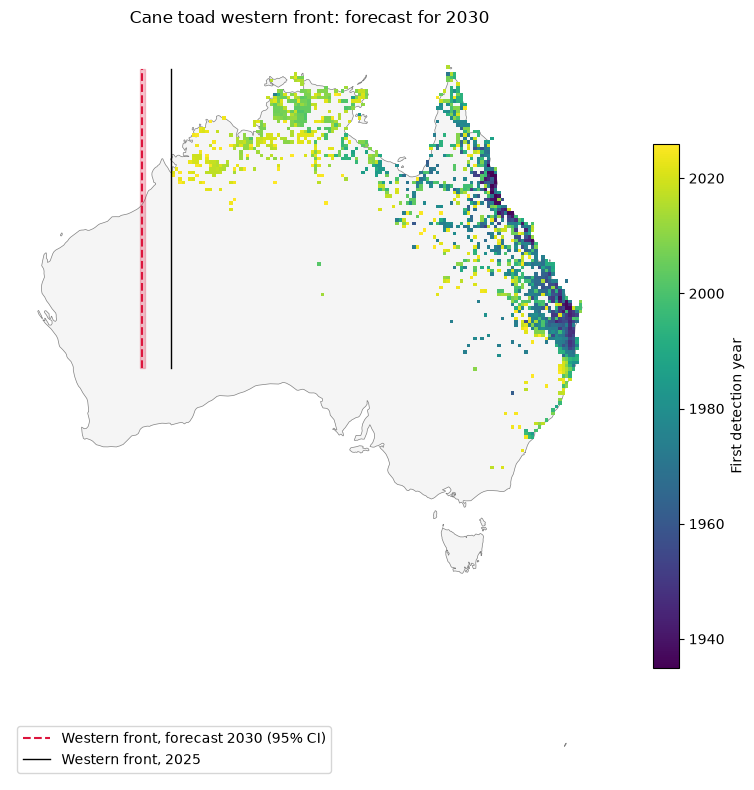

In [10]:
fig, ax = plt.subplots(figsize=(9, 8))
australia.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
plot_cells(ax, cells, "first_year", "viridis", "First detection year")

to_x = lambda advance_km: -advance_km * 1000
ax.axvspan(to_x(forecast_2030["high"]), to_x(forecast_2030["low"]), ymin=0.55, ymax=0.95, color="crimson", alpha=0.25)
ax.axvline(to_x(forecast_2030["median"]), ymin=0.55, ymax=0.95, color="crimson", linestyle="--",
           label="Western front, forecast 2030 (95% CI)")
ax.axvline(to_x(front_2025_km), ymin=0.55, ymax=0.95, color="black", linewidth=1, label="Western front, 2025")
ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_title("Cane toad western front: forecast for 2030")
plt.tight_layout()
plt.savefig(FIGURES / "02_forecast_2030.png", dpi=150)

The confidence interval only reflects the uncertainty of the slope. The backtest showed a systematic bias (the front slowed down), so the real uncertainty is larger, and **this forecast is more likely to be too far west than too short.**

## 7. The southern front: the data cannot tell

The same method applied to the southern front:

In [11]:
south_cells = cells.loc[(cells["lat"] < -25) & (cells["lon"] > 148)]
south_strips = strip_arrivals(south_cells, "y_km", STRIP_KM)
south_recent = south_strips.loc[south_strips["arrival_year"] >= 1960]
s_slope, _, s_low, s_high = theilslopes(south_recent["advance_km"], south_recent["arrival_year"])
print(f"Southern front, 1960-2025: {s_slope:.1f} km/year (95% CI {s_low:.1f} to {s_high:.1f}), {len(south_recent)} strips")

Southern front, 1960-2025: 8.0 km/year (95% CI -4.7 to 16.7), 16 strips


The confidence interval includes zero: **with these data we cannot estimate a southern spread rate.** That is a result in itself. The southern front is not a travelling wave like the western one; it is a slow, probably climate-limited boundary, blurred by toads transported by people (e.g. the Sydney population). Answering this requires climate data (notebook 03) and probably a different model.

## 8. How much of Australia has been invaded?

Another way to look at the invasion: the **area occupied** each year. An occupied cell is one with at least one record up to that year. Because the answer depends on the cell size, we compute it with three grids: 10, 25 and 50 km per side.

,10 km,25 km,50 km
1940,0.06,0.24,0.72
1960,0.29,1.17,2.63
1980,1.13,4.10,8.81
2000,1.94,5.93,11.93
2010,2.65,7.90,15.41
2025,4.15,11.39,21.39


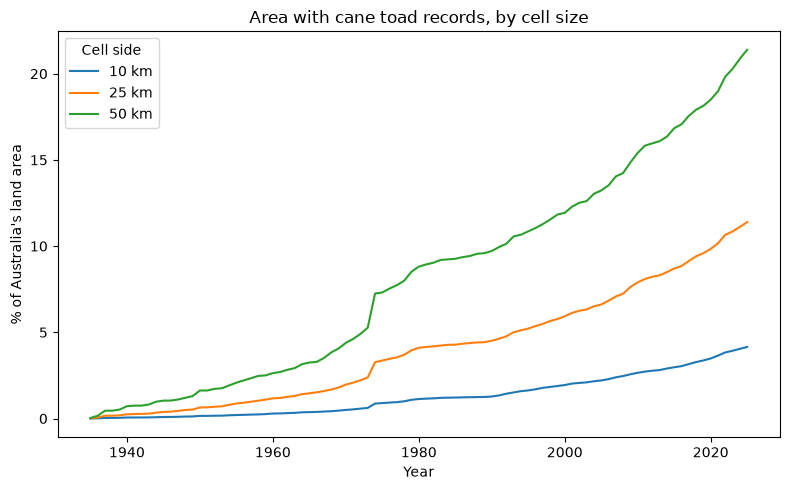

In [12]:
AUSTRALIA_KM2 = australia.area.sum() / 1e6
CELL_SIZES_KM = [10, 25, 50]
YEARS_AREA = np.arange(1935, 2026)

occupied_area = pd.DataFrame({
    f"{size} km": [
        (records_to_cells(records, size * 1000)["first_year"] <= year).sum() * size**2
        for year in YEARS_AREA
    ]
    for size in CELL_SIZES_KM
}, index=YEARS_AREA)
occupied_pct = 100 * occupied_area / AUSTRALIA_KM2

ax = occupied_pct.plot(figsize=(8, 5))
ax.set(xlabel="Year", ylabel="% of Australia's land area", title="Area with cane toad records, by cell size")
ax.legend(title="Cell side")
plt.tight_layout()
plt.savefig(FIGURES / "02_occupied_area.png", dpi=150)

occupied_pct.loc[[1940, 1960, 1980, 2000, 2010, 2025]].round(2)

**The same data say 4%, 11% or 21% of Australia, depending on the grid.** A cell of 50 km counts as occupied with a single record anywhere inside its 2,500 km². That's not a bug of this analysis: area of occupancy is scale-dependent by definition, which is why the IUCN Red List fixes it at 2 × 2 km cells to make species comparable.

The shape of the curve is consistent across scales: slow growth until ~1960, acceleration in 1960–1980, a plateau in the 1980s–90s, and steady growth since 2000 driven by the western front.

### A second estimate of speed? (Skellam)

In the classic reaction-diffusion model (Skellam 1951), a population spreading **in all directions** over a **homogeneous** landscape occupies a growing circle whose radius increases linearly with time. So the "equivalent radius" √(area / π) should grow at the speed of the front. Does it match the 43 km/year from Theil–Sen?

In [13]:
radius = np.sqrt(occupied_area.loc[1996:2025] / np.pi)
skellam = {}
for size in radius.columns:
    radial_speed, _, radial_low, radial_high = theilslopes(radius[size], radius.index)
    skellam[size] = {"km/year": radial_speed, "95% CI low": radial_low, "95% CI high": radial_high}
pd.DataFrame(skellam).T.round(1)

,km/year,95% CI low,95% CI high
10 km,3.8,3.6,4.0
25 km,5.7,5.5,5.8
50 km,6.8,6.6,7.1


**No: 4–7 km/year, about ten times slower than the western front.** The disagreement is informative, because it shows which assumptions of Skellam's model are broken:

1. **The spread is not radial.** Toads advance along a single front (the west) while the south is almost stalled; half of the "circle" is ocean and much of the interior is desert. The area grows like a band that gets longer, not like a circle that gets wider.
2. **Recorded area is not invaded area.** Records follow roads and towns; most of the land behind the front is invaded but never recorded.

The lesson for the library: **a method is only valid when its assumptions hold**, and comparing two estimators built on different assumptions is a cheap way to detect when they don't.

## Takeaways and limitations

- **Estimator choice matters more than the model.** Front estimates based on the most advanced records are dominated by transported toads and sampling gaps.
- **Western front:** about 43 km/year (1996–2025). The backtest predicted 2016–2025 arrivals within about 1.5 years, with a bias showing the front is **slowing down**.
- **Southern front:** not estimable from occurrence data alone.
- **Occupied area:** 4–21% of Australia in 2025 depending on the grid (10–50 km). Area is scale-dependent; Skellam's radial model underestimates the front speed tenfold because the spread is not radial.

**What this model ignores:**
1. **Climate and habitat.** A linear extrapolation assumes constant speed, but the western front is approaching the arid Pilbara. → Notebook 03 (habitat suitability).
2. **Detection lag** and changes in survey effort.
3. **Direction.** The western front moves south-west along the Kimberley coast; measuring it on the x axis alone simplifies that.